<a href="https://colab.research.google.com/github/ansumanbebarta/abc/blob/master/E26133013_Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
!pip install datasets

import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

In [18]:
dataset = load_dataset("gvlassis/california_housing")
train_df, val_df, test_df = ( dataset[k].to_pandas() for k in ['train', 'validation', 'test'])

In [19]:
X_train, X_val, X_test = (df.drop(columns='MedHouseVal') for df in [train_df, val_df, test_df])

In [20]:
y_train, y_val, y_test = (df['MedHouseVal'] for df in [train_df, val_df, test_df])

In [21]:
model = Ridge(alpha=1.0).fit(X_train, y_train)

In [22]:
test_loss = mean_squared_error(y_test, model.predict(X_test)) * len(y_test)
print(f'Test loss: {test_loss}')

Test loss: 683.0534763273502


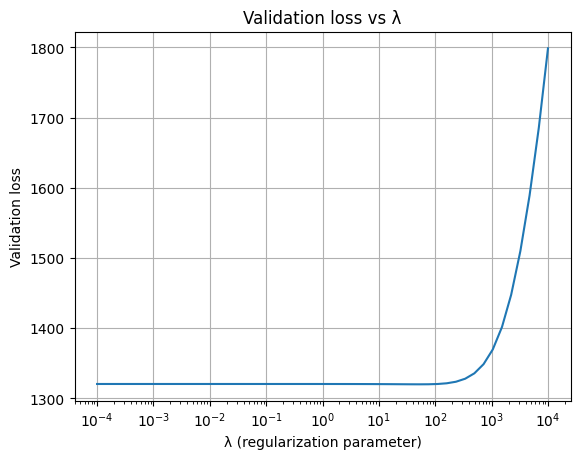

Best λ: 51.79474679231202
Test loss at best λ: 679.7128262556735


In [24]:
lambdas = np.logspace(-4, 4, 50)
val_losses = []
for lambda_ in lambdas:
    model = Ridge(alpha=lambda_)
    model.fit(X_train, y_train)
    y_val_hat = model.predict(X_val)
    val_loss = mean_squared_error(y_val, y_val_hat) * len(y_val)
    val_losses.append(val_loss)

plt.plot(lambdas, val_losses)
plt.xscale('log')
plt.xlabel("λ (regularization parameter)")
plt.ylabel("Validation loss")
plt.title("Validation loss vs λ")
plt.grid(True)
plt.show()

best_lambda = lambdas[np.argmin(val_losses)]
best_model = Ridge(alpha=best_lambda).fit(X_train, y_train)
test_loss_best = mean_squared_error(y_test, best_model.predict(X_test)) * len(y_test)
print("Best λ:", best_lambda)
print("Test loss at best λ:", test_loss_best)